# ¿Puede una API de IA inspeccionar la calidad de una placa?
### DecisionAPI con GPT-6-luna frente a YOLO11n-cls · Un laboratorio explicado para profesionales de TI

**Finalidad de la comparación.** Queremos saber qué alternativa ofrece una mejor base para identificar defectos visibles en fotografías de placas electrónicas: una API que recibe instrucciones en lenguaje natural o un modelo de visión entrenado con ejemplos del problema. La pregunta práctica es cuánto podemos confiar en sus decisiones antes de integrarlas a un proceso empresarial o industrial.

En una línea de calidad, una placa defectuosa que pasa inadvertida puede llegar al cliente. Una placa sana marcada como defectuosa genera revisiones, retrabajo o descarte. Por eso comparamos **defectos detectados, defectos que se escapan, falsas alarmas y aciertos generales**. También revisamos tiempos y reproducibilidad, con sus límites.

**Viabilidad industrial.** Los resultados favorecen a YOLO como candidato para un piloto de inspección visual de este tipo. Su entrenamiento requiere imágenes etiquetadas y mantenimiento. La API facilita experimentar con instrucciones, pero la configuración evaluada deja escapar demasiados defectos para recomendarla como único filtro automático. Ambos necesitan una validación con piezas, cámaras, tiempos y criterios de aceptación de la operación real.


## El resultado en un minuto

**YOLO es el ganador de esta prueba.** Sobre las mismas 60 imágenes, acertó en 56 y encontró 29 de las 30 placas con anomalías. DecisionAPI acertó en 49 y encontró 23 de esas 30 placas.

| Lo que importa en la inspección | YOLO11n-cls | DecisionAPI · GPT-6-luna · V1 |
|---|---:|---:|
| Defectos detectados, de 30 | **29** | 23 |
| Defectos que pasaron inadvertidos | **1** | 7 |
| Placas sanas con falsa alarma, de 30 | **3** | 4 |
| Aciertos totales, de 60 | **56 (93,33%)** | 49 (81,67%) |

La diferencia más relevante es operativa: **YOLO dejó pasar seis defectos menos**, sin aumentar las falsas alarmas. La ventaja observada es de **20 puntos porcentuales en detección de anomalías** y **11,67 puntos en aciertos generales**.

Nuestra conclusión es que **la beta de DecisionAPI con GPT-6-luna aún no muestra la madurez necesaria para asumir por sí sola esta tarea de inspección industrial en la configuración probada**. El resultado corresponde a este laboratorio: YOLO recibió entrenamiento específico y la API se evaluó sin ese ajuste.


## Cómo leer y utilizar este notebook

La lectura principal explica el problema, los gráficos y la decisión. Al final hay una ruta de reproducción y referencias técnicas para profundizar. No necesitas experiencia en IA para seguirla.

- **Para leer:** los gráficos y tablas ya están guardados dentro del notebook.
- **Para recalcular los gráficos:** ejecuta las celdas de arriba hacia abajo con las dependencias de análisis indicadas al final. Solo se leen CSV y JSON locales; no se necesita GPU ni una clave de API.
- **Para repetir el experimento:** consulta la guía enlazada al final. Este notebook describe los pasos y enlaza los scripts; no incluye comandos de pruebas de DecisionAPI ni de YOLO.

Las celdas de código contienen únicamente lectura, comprobaciones y visualización de la evidencia conservada.


## 1. Dos formas de responder la misma pregunta

La pregunta es sencilla: **«¿Esta foto de una placa muestra una anomalía visible?»** Una anomalía es un defecto anotado en el conjunto de imágenes, como un componente ausente o un daño superficial.

| | DecisionAPI con GPT-6-luna | YOLO11n-cls |
|---|---|---|
| Cómo se preparó | Una instrucción o *prompt* describe qué observar | Se ajustó un modelo preentrenado con fotos etiquetadas |
| Qué recibe | Imagen y pregunta sobre un defecto visible | Imagen de una placa |
| Qué usamos de su respuesta | Una probabilidad de anomalía | Una probabilidad de la clase anomalía |
| Dónde se ejecutó | Servicio remoto mediante API | Equipo local con GPU |
| Trabajo previo específico | Exploración del prompt y elección del umbral | Entrenamiento y elección del umbral |

**En esta prueba ambos clasifican la imagen completa como normal o anómala.** La variante `-cls` de YOLO utilizada no dibuja cajas ni señala la ubicación del defecto. Tampoco una foto permite certificar que la placa funcione eléctricamente.

La [guía oficial de Decisions API](https://developers.openai.com/api/docs/guides/decisions), consultada el 15 de octubre de 2026, describe una beta pública con GPT-6-luna y respuestas de tipo probabilidad, elección o puntuación. Aquí se utilizó una pregunta de tipo `predicate` llamada `visible_defect`. La [documentación de clasificación de Ultralytics](https://docs.ultralytics.com/tasks/classify/) explica la modalidad de clasificación por imagen.


## 2. Cómo se organizó una comparación verificable

Usamos imágenes de **VisA, categoría pcb1**, publicado por Amazon Science y colaboradores. La categoría contiene 1.004 imágenes normales y 100 anómalas. Los datos están disponibles bajo CC BY 4.0 y requieren atribución: [fuente y descarga oficiales](https://github.com/amazon-science/spot-diff).

Separamos las fotos por función, como en un curso con ejercicios y examen:

1. **Exploración, 20 imágenes:** probar dos formas de preguntar a la API, V1 y V2.
2. **Entrenamiento, 240 imágenes:** enseñar a YOLO con 200 placas normales y 40 anómalas.
3. **Validación, 40 imágenes:** elegir los pesos de YOLO y los umbrales de decisión de ambos sistemas.
4. **Prueba final o test, 60 imágenes:** comparar ambos sistemas sobre las mismas 30 placas normales y 30 anómalas.

Esta es una **partición local**, no el protocolo oficial de VisA. Se verificó que las imágenes asignadas no se repitieran entre conjuntos por ruta ni por contenido exacto. No se verificó separación por lote o pieza física.


In [1]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

def find_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'results/audit_20261013/comparison_test.json').is_file():
            return candidate
    raise FileNotFoundError('Abre el notebook desde la carpeta del proyecto o notebooks/.')

ROOT = find_root()
AUDIT = ROOT / 'results/audit_20261013'
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

comparison = read_json(AUDIT / 'comparison_test.json')
historical = read_json(AUDIT / 'historical_metrics_recomputed.json')
split = pd.read_csv(ROOT / 'data/pcb1_splits.csv')
paired = pd.read_csv(AUDIT / 'paired_test.csv')
yolo_rows = pd.read_csv(AUDIT / 'yolo_predictions_test.csv')
api_rows = pd.read_csv(ROOT / 'results/runs/v1_test/predictions.csv')
frozen_yolo = read_json(AUDIT / 'yolo_threshold_frozen.json')
frozen_api = read_json(ROOT / 'results/selected_threshold.json')

YOLO, API = '#007F86', '#BC620C'
INK, MUTED, GRID = '#162B40', '#536678', '#DFE7ED'
MISS, PALE = '#B13F57', '#E8EEF2'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': INK, 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
    'ytick.color': INK, 'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 15, 'axes.titleweight': 'bold', 'axes.titlepad': 16,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 120, 'savefig.dpi': 140,
})
def pct(value):
    return f'{value * 100:.2f}%'.replace('.', ',')
def clean_axis(ax):
    ax.spines[['left', 'bottom']].set_visible(False)
    ax.tick_params(length=0)
    ax.set_axisbelow(True)
    ax.grid(axis='x', color=GRID, linewidth=0.8)
def foot(fig, text):
    fig.text(0.02, 0.015, text, fontsize=9, color=MUTED, va='bottom')

print('Evidencia local cargada. No se ejecutaron modelos ni llamadas a la API.')


Evidencia local cargada. No se ejecutaron modelos ni llamadas a la API.


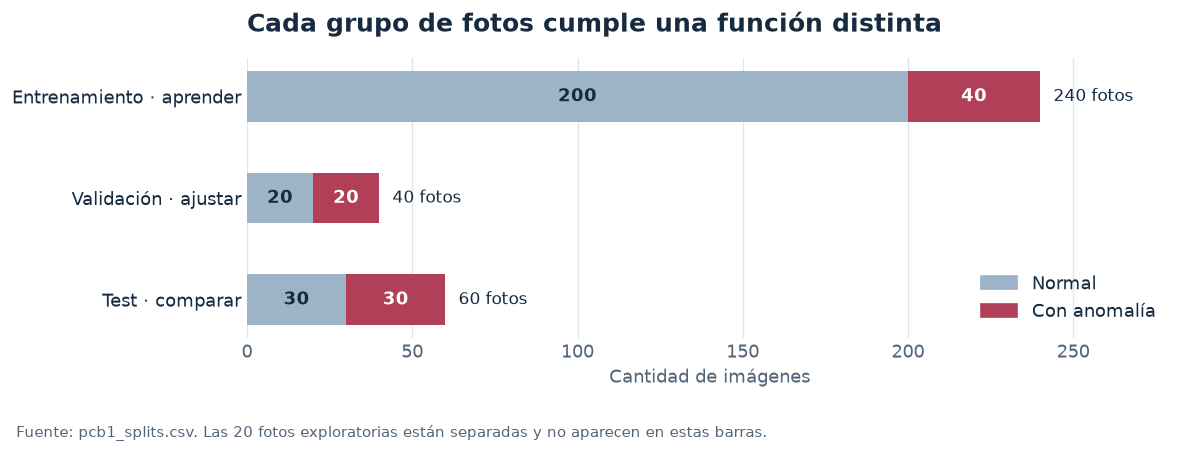

In [2]:
counts = pd.crosstab(split['split'], split['ground_truth']).reindex(['train', 'validation', 'test'])
assert counts['normal'].tolist() == [200, 20, 30]
assert counts['anomaly'].tolist() == [40, 20, 30]
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = ['Entrenamiento · aprender', 'Validación · ajustar', 'Test · comparar']
for i, label in enumerate(labels):
    normal, anomaly = counts.iloc[i][['normal', 'anomaly']]
    ax.barh(i, normal, color='#9DB3C8', height=.5)
    ax.barh(i, anomaly, left=normal, color=MISS, height=.5)
    ax.text(normal / 2, i, str(normal), va='center', ha='center', color=INK, weight='bold')
    ax.text(normal + anomaly / 2, i, str(anomaly), va='center', ha='center', color='white', weight='bold')
    ax.text(normal + anomaly + 4, i, f'{normal + anomaly} fotos', va='center', fontsize=10)
ax.set_yticks(range(3), labels)
ax.invert_yaxis()
ax.set_xlim(0, 280)
ax.set_xlabel('Cantidad de imágenes')
ax.set_title('Cada grupo de fotos cumple una función distinta', loc='left')
clean_axis(ax)
ax.legend(handles=[Patch(color='#9DB3C8', label='Normal'), Patch(color=MISS, label='Con anomalía')],
          loc='lower right', frameon=False)
foot(fig, 'Fuente: pcb1_splits.csv. Las 20 fotos exploratorias están separadas y no aparecen en estas barras.')
fig.tight_layout(rect=(0, .09, 1, 1))
plt.show()


### Cómo pasamos de una probabilidad a una decisión

El **umbral** es el punto a partir del cual una imagen se marca como anómala. Una probabilidad igual o mayor al umbral activa la alerta. Bajar el umbral suele detectar más defectos, pero también puede generar más falsas alarmas.

En validación se buscó detectar la mayor cantidad de anomalías manteniendo las falsas alarmas en un máximo observado del 10% de las placas normales. Los desempates se resolvieron con F1, luego menor tasa de falsas alarmas y finalmente el primer umbral de la grilla ascendente. Se fijaron **0,20 para DecisionAPI y 0,50 para YOLO**, antes de evaluar el test de cada sistema.

Usar umbrales diferentes es razonable: las puntuaciones provienen de sistemas distintos. No se ha demostrado que una probabilidad de 0,80 corresponda a un 80% de defectos reales. La selección del umbral es un ajuste operativo; no demuestra calibración de probabilidades.

La API se comparó con **V1**. En la exploración, V2 detectó 7 de 10 anomalías frente a 6 de V1, pero produjo 6 falsas alarmas frente a ninguna de V1; sus aciertos generales bajaron del 80% al 55%. Una instrucción más detallada no mejoró el equilibrio en esa muestra. Es un resultado exploratorio de 20 fotos, sin demostración de la causa del cambio. Los [prompts conservados y sus límites de trazabilidad](../docs/prompts.md) permiten profundizar.


In [3]:
# Recalculamos las métricas desde cada CSV, sin usar los totales escritos en la introducción.
assert len(paired) == 60 and paired['image'].is_unique
test_manifest = split.loc[split['split'].eq('test')].set_index('image')
assert set(paired['image']) == set(test_manifest.index)
assert paired['ground_truth'].eq(paired['image'].map(test_manifest['ground_truth'])).all()
assert paired['ground_truth'].value_counts().to_dict() == {'anomaly': 30, 'normal': 30}
thresholds = {'yolo': frozen_yolo['selection']['threshold'],
              'decisions_api': frozen_api['selection']['threshold']}
assert thresholds == {'yolo': .5, 'decisions_api': .2}
metrics = {}
for key, rows, col in [('yolo', yolo_rows, 'yolo'), ('decisions_api', api_rows, 'api')]:
    assert len(rows) == 60 and rows['image'].is_unique
    assert set(rows['image']) == set(paired['image'])
    rows = rows.set_index('image').loc[paired['image']]
    assert np.array_equal(rows['ground_truth'].values, paired['ground_truth'].values)
    assert np.allclose(rows['probability'], paired[f'{col}_probability'], rtol=0, atol=1e-12)
    if key == 'decisions_api':
        assert rows['status'].eq('ok').all()
        assert rows['model'].eq('gpt-6-luna').all() and rows['prompt_version'].eq('v1').all()
    truth = paired['ground_truth'].eq('anomaly').to_numpy()
    pred = rows['probability'].to_numpy() >= thresholds[key]
    assert np.array_equal(np.where(pred, 'anomaly', 'normal'), paired[f'{col}_prediction'])
    tp, tn = int((truth & pred).sum()), int((~truth & ~pred).sum())
    fp, fn = int((~truth & pred).sum()), int((truth & ~pred).sum())
    m = dict(tp=tp, tn=tn, fp=fp, fn=fn, accuracy=(tp+tn)/60,
             precision=tp/(tp+fp), recall=tp/(tp+fn), f1=2*tp/(2*tp+fp+fn),
             fpr=fp/(fp+tn), fnr=fn/(tp+fn))
    for field, value in m.items():
        assert math.isclose(value, comparison[key][field], rel_tol=0, abs_tol=1e-12)
    metrics[key] = m
Y, A = metrics['yolo'], metrics['decisions_api']
print('Verificado: mismas 60 imágenes, umbrales fijados, modelo/prompt API y métricas coincidentes.')


Verificado: mismas 60 imágenes, umbrales fijados, modelo/prompt API y métricas coincidentes.


## 3. El gráfico clave: ¿cuántos defectos se escaparon?

Cada círculo representa **una de las 30 placas con anomalía**. Los círculos llenos son defectos detectados; las cruces representan defectos que el sistema consideró normales.

Esta es la medida llamada **recall o sensibilidad**: de los defectos que realmente existían, ¿cuántos encontramos? Para este escenario es el principal argumento a favor de YOLO.


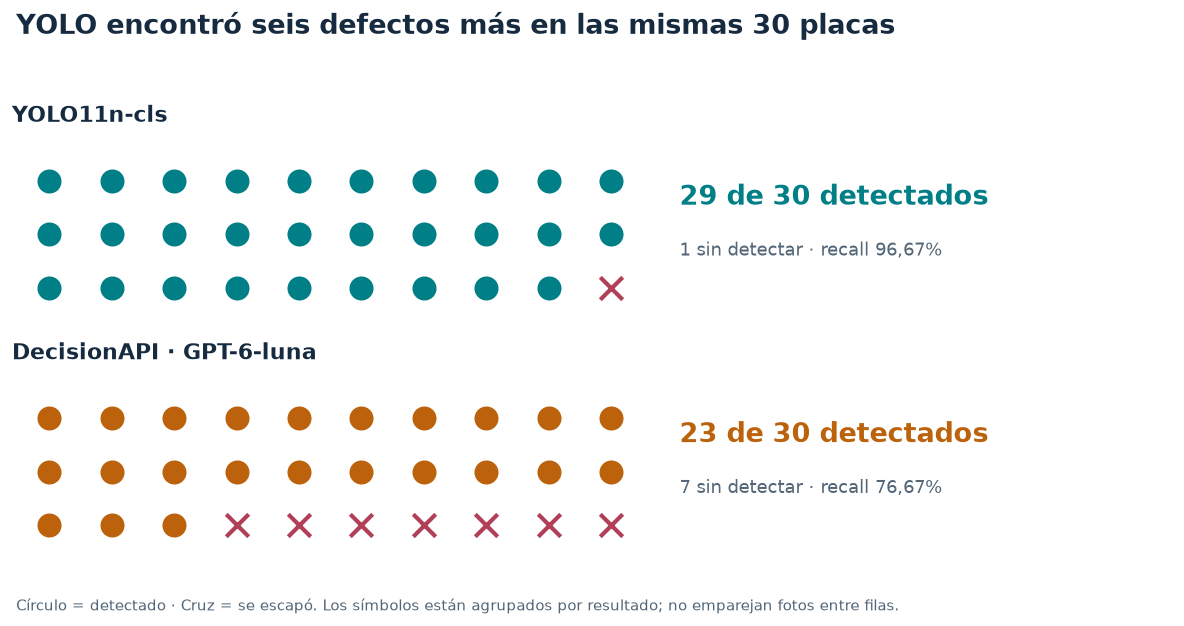

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.2))
for ax, name, m, color in [(axes[0], 'YOLO11n-cls', Y, YOLO),
                          (axes[1], 'DecisionAPI · GPT-6-luna', A, API)]:
    x = np.tile(np.arange(10), 3)
    y = np.repeat([2, 1, 0], 10)
    found = np.arange(30) < m['tp']
    ax.scatter(x[found], y[found], s=180, c=color, marker='o')
    ax.scatter(x[~found], y[~found], s=180, c=MISS, marker='x', linewidths=2.5)
    ax.text(10.1, 1.55, f"{m['tp']} de 30 detectados", fontsize=16, weight='bold', color=color)
    ax.text(10.1, .6, f"{m['fn']} sin detectar · recall {pct(m['recall'])}", fontsize=11, color=MUTED)
    ax.set_title(name, loc='left', fontsize=13)
    ax.set_xlim(-.6, 18)
    ax.set_ylim(-.65, 2.6)
    ax.axis('off')
fig.suptitle('YOLO encontró seis defectos más en las mismas 30 placas', x=.02, ha='left', fontsize=16, weight='bold')
foot(fig, 'Círculo = detectado · Cruz = se escapó. Los símbolos están agrupados por resultado; no emparejan fotos entre filas.')
fig.tight_layout(rect=(0, .07, 1, .94))
plt.show()


### También importan las falsas alarmas

Un **falso negativo (FN)** es una placa defectuosa que pasa como normal. Un **falso positivo (FP)** es una placa sana que genera una alarma. El daño económico de cada error depende del proceso; aquí no se midió en dinero.

YOLO redujo los defectos omitidos de 7 a 1 y también generó una falsa alarma menos. Por eso su mejor detección no se consiguió a costa de enviar más placas sanas a revisión.


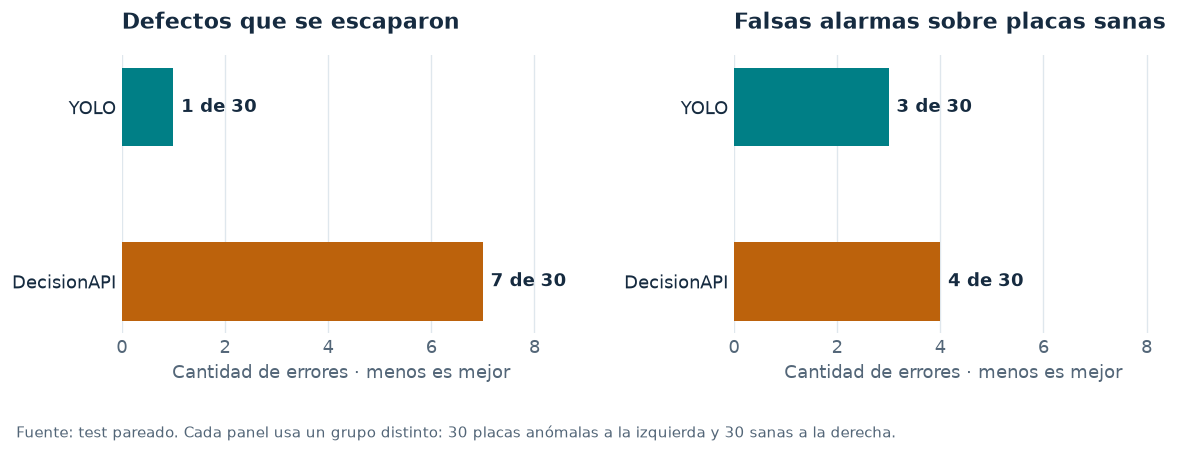

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, field, title, total in [(axes[0], 'fn', 'Defectos que se escaparon', 30),
                                (axes[1], 'fp', 'Falsas alarmas sobre placas sanas', 30)]:
    values = [Y[field], A[field]]
    bars = ax.barh([0, 1], values, height=.45, color=[YOLO, API])
    ax.set_yticks([0, 1], ['YOLO', 'DecisionAPI'])
    ax.invert_yaxis()
    ax.set_xlim(0, 8.5)
    ax.set_xticks([0, 2, 4, 6, 8])
    ax.set_title(title, loc='left', fontsize=13)
    ax.set_xlabel('Cantidad de errores · menos es mejor')
    clean_axis(ax)
    for bar, value in zip(bars, values):
        ax.text(value+.15, bar.get_y()+bar.get_height()/2, f'{value} de {total}', va='center', weight='bold')
foot(fig, 'Fuente: test pareado. Cada panel usa un grupo distinto: 30 placas anómalas a la izquierda y 30 sanas a la derecha.')
fig.tight_layout(rect=(0, .1, 1, 1), w_pad=3)
plt.show()


## 4. Una visión completa de la calidad

Estas métricas responden a preguntas distintas. En las tres, un valor más alto es mejor:

| Métrica | En lenguaje cotidiano | Denominador en este test |
|---|---|---|
| **Aciertos generales (accuracy)** | ¿Cuántas decisiones fueron correctas? | Las 60 imágenes |
| **Detección de defectos (recall)** | ¿Cuántas placas con anomalía detectamos? | Las 30 anómalas |
| **Alertas correctas (precision)** | De las alertas emitidas, ¿cuántas eran defectos reales? | 32 alertas YOLO; 27 API |

No confundas *precision* con aciertos generales. Una planta con muy pocos defectos puede tener muchos aciertos aunque deje escapar defectos: la proporción de piezas sanas cambia la interpretación.


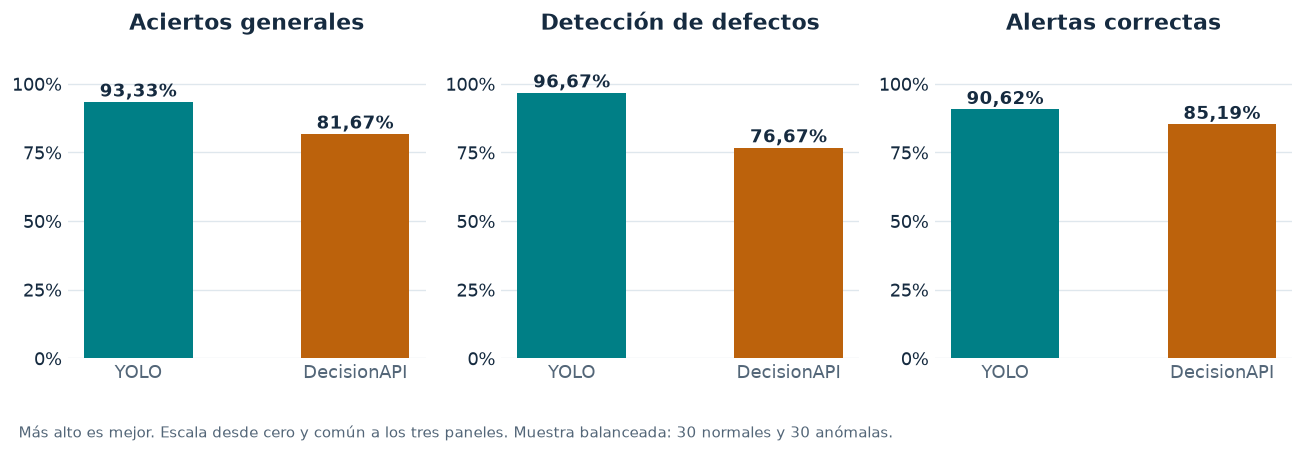

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, field, title in zip(axes, ['accuracy', 'recall', 'precision'],
                           ['Aciertos generales', 'Detección de defectos', 'Alertas correctas']):
    values = [Y[field]*100, A[field]*100]
    bars = ax.bar([0, 1], values, width=.5, color=[YOLO, API])
    ax.set_xticks([0, 1], ['YOLO', 'DecisionAPI'])
    ax.set_ylim(0, 110)
    ax.set_yticks([0, 25, 50, 75, 100], ['0%', '25%', '50%', '75%', '100%'])
    ax.set_title(title, fontsize=13)
    ax.set_axisbelow(True)
    ax.grid(axis='y', color=GRID)
    ax.spines[['left', 'bottom']].set_visible(False)
    ax.tick_params(length=0)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x()+bar.get_width()/2, value+2, pct(value/100), ha='center', weight='bold')
foot(fig, 'Más alto es mejor. Escala desde cero y común a los tres paneles. Muestra balanceada: 30 normales y 30 anómalas.')
fig.tight_layout(rect=(0, .1, 1, 1))
plt.show()


**Lectura del gráfico:** YOLO aventaja a la API en las tres métricas. El F1, que combina detección y alertas correctas, también favorece a YOLO: **0,9355 frente a 0,8070**. La conclusión se apoya en los errores y aciertos observados; estos resultados no explican por sí solos la causa de cada error.

### ¿Qué ocurre con cada tipo de placa?

El siguiente gráfico reúne las cuatro situaciones posibles. Permite ver tanto lo que un sistema acierta como lo que habría que revisar en un proceso de calidad.


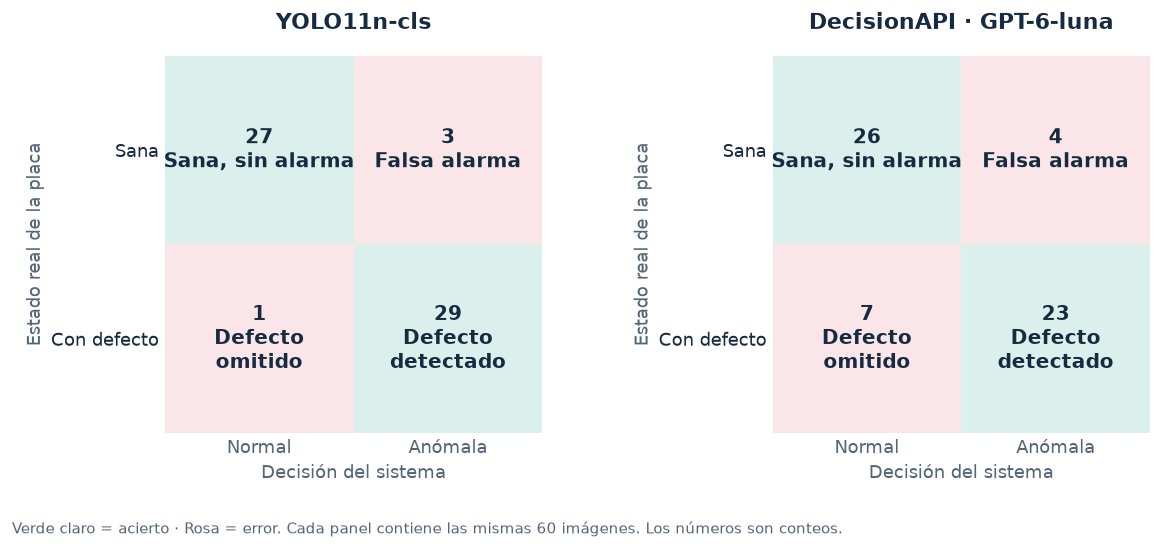

In [7]:
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, name, m in [(axes[0], 'YOLO11n-cls', Y), (axes[1], 'DecisionAPI · GPT-6-luna', A)]:
    ax.imshow([[0, 1], [1, 0]], cmap=ListedColormap(['#DBF0ED', '#FAE6E9']), vmin=0, vmax=1)
    texts = [[f"{m['tn']}\nSana, sin alarma", f"{m['fp']}\nFalsa alarma"],
             [f"{m['fn']}\nDefecto\nomitido", f"{m['tp']}\nDefecto\ndetectado"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, texts[i][j], ha='center', va='center', fontsize=12, weight='bold')
    ax.set_xticks([0, 1], ['Normal', 'Anómala'])
    ax.set_yticks([0, 1], ['Sana', 'Con defecto'])
    ax.set_xlabel('Decisión del sistema')
    ax.set_ylabel('Estado real de la placa')
    ax.set_title(name, fontsize=13)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
foot(fig, 'Verde claro = acierto · Rosa = error. Cada panel contiene las mismas 60 imágenes. Los números son conteos.')
fig.tight_layout(rect=(0, .08, 1, 1), w_pad=3)
plt.show()


## 5. Lo que nos enseña pasar de validación a test

En validación, ambos sistemas encontraron el 95% de las anomalías. En la prueba final, YOLO encontró el 96,67% y la API el 76,67%. **Una buena validación no garantiza el mismo resultado con imágenes diferentes.**

La línea del gráfico une conjuntos distintos para facilitar la comparación; no representa una evolución en el tiempo. La muestra de validación se usó para elegir configuraciones, así que su resultado puede ser optimista.


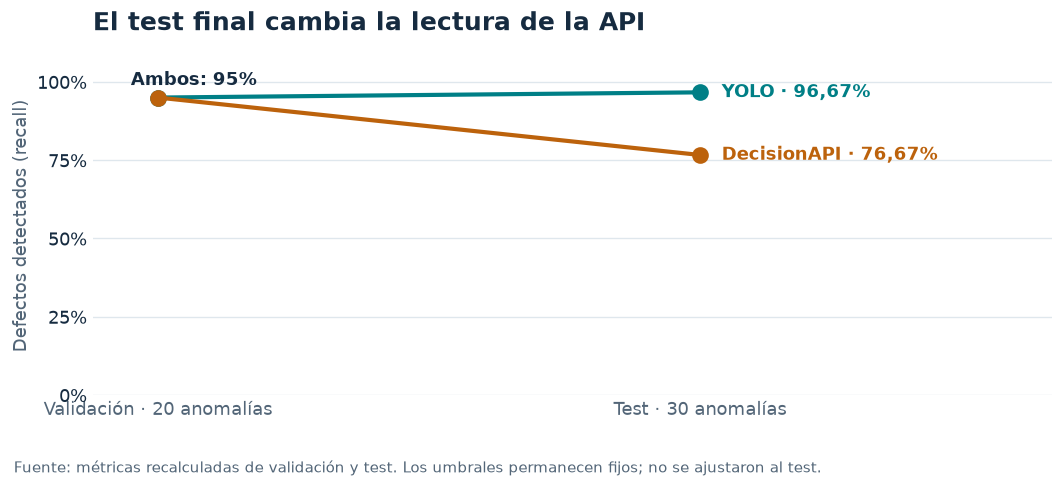

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.1))
for name, color, val, test in [
    ('YOLO', YOLO, historical['YOLO_validation']['recall'], Y['recall']),
    ('DecisionAPI', API, historical['API_validation_v1']['recall'], A['recall'])]:
    ax.plot([0, 1], [100*val, 100*test], color=color, linewidth=2.5, marker='o', markersize=9, label=name)
    ax.text(1.04, 100*test, f'{name} · {pct(test)}', color=color, va='center', weight='bold')
ax.text(-.05, 99, 'Ambos: 95%', weight='bold')
ax.set_xticks([0, 1], ['Validación · 20 anomalías', 'Test · 30 anomalías'])
ax.set_xlim(-.12, 1.65)
ax.set_ylim(0, 108)
ax.set_yticks([0, 25, 50, 75, 100], ['0%', '25%', '50%', '75%', '100%'])
ax.set_ylabel('Defectos detectados (recall)')
ax.set_title('El test final cambia la lectura de la API', loc='left')
ax.set_axisbelow(True)
ax.grid(axis='y', color=GRID)
ax.spines[['left', 'bottom']].set_visible(False)
ax.tick_params(length=0)
foot(fig, 'Fuente: métricas recalculadas de validación y test. Los umbrales permanecen fijos; no se ajustaron al test.')
fig.tight_layout(rect=(0, .09, 1, 1))
plt.show()


### Cuánta confianza podemos tener en esta diferencia

La ventaja de YOLO es clara en los conteos, pero **30 placas anómalas son pocas para estimar una tasa industrial**. Cada defecto adicional detectado u omitido cambia el recall en 3,33 puntos porcentuales.

Los intervalos del gráfico muestran la incertidumbre muestral del recall (Wilson al 95%). Un intervalo más amplio indica menor precisión de la estimación. No representan una garantía para una planta ni incluyen la incertidumbre por selección del modelo y umbral.


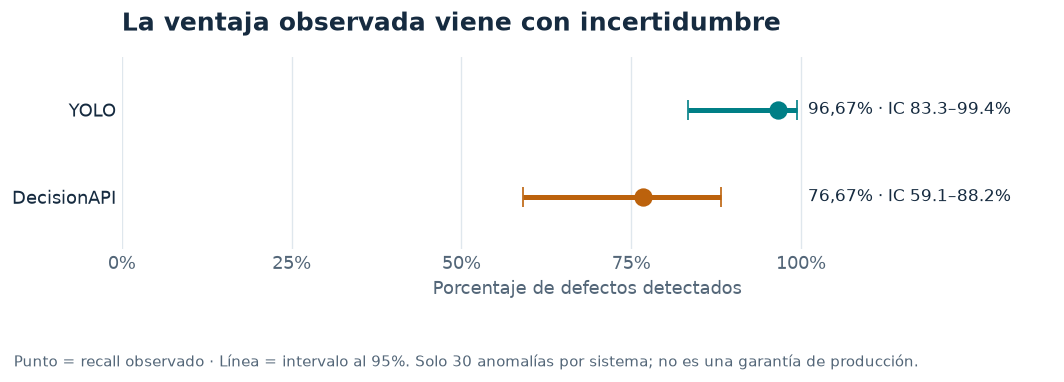

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, key, name, color in [(0, 'yolo', 'YOLO', YOLO), (1, 'decisions_api', 'DecisionAPI', API)]:
    point = metrics[key]['recall']*100
    lo, hi = np.array(comparison[key]['recall_ci95_wilson'])*100
    ax.errorbar(point, i, xerr=[[point-lo], [hi-point]], fmt='o', markersize=10,
                color=color, capsize=6, linewidth=3)
    ax.text(101, i, f'{pct(point/100)} · IC {lo:.1f}–{hi:.1f}%', va='center', fontsize=10)
ax.set_yticks([0, 1], ['YOLO', 'DecisionAPI'])
ax.set_ylim(1.6, -.6)
ax.set_xlim(0, 137)
ax.set_xticks([0, 25, 50, 75, 100], ['0%', '25%', '50%', '75%', '100%'])
ax.set_xlabel('Porcentaje de defectos detectados')
ax.set_title('La ventaja observada viene con incertidumbre', loc='left')
clean_axis(ax)
foot(fig, 'Punto = recall observado · Línea = intervalo al 95%. Solo 30 anomalías por sistema; no es una garantía de producción.')
fig.tight_layout(rect=(0, .15, 1, 1))
plt.show()


Para una lectura estadística más técnica: ambos sistemas acertaron en 48 imágenes y fallaron en 3; YOLO acertó en 8 donde la API falló y la API acertó en 1 donde YOLO falló. La prueba pareada de McNemar exacta bilateral da **p = 0,0391**. Es evidencia exploratoria de diferencia en este experimento; no demuestra superioridad universal ni sustituye una validación industrial. El solapamiento de intervalos individuales tampoco reemplaza el análisis pareado.

El diagnóstico posterior encontró que **ningún defecto omitido fue común a ambos métodos** y que tres falsas alarmas sí fueron comunes. Eso invita a estudiar sus errores; no demuestra que combinarlos produzca un sistema mejor. Las máscaras se usaron después para revisar las regiones anotadas, nunca como entrada a los modelos. El análisis no respalda atribuir los fallos a que el recorte haya eliminado por completo el defecto. Detalle: [reporte y diagnóstico](../reports/comparacion-20261013.md).


## 6. Velocidad y coste: lo que medimos y lo que falta

En los registros, la inferencia local de YOLO tardó menos que la consulta a la API. Sin embargo, **los tiempos se midieron de formas diferentes**: en la API intervienen red, servicio y posibles reintentos; en YOLO, arranque, preprocesado e inferencia local.

| Registro del test | Media observada | Cómo leerlo |
|---|---:|---|
| YOLO, incluyendo primera llamada | 27,34 ms | Incluye el efecto de arranque |
| YOLO, excluyendo primera llamada | 19,61 ms | Cálculo sobre las 59 restantes |
| DecisionAPI, registro histórico | 1.062,13 ms | Consulta remota con red y servicio |

Estos datos orientan un piloto, pero **no permiten afirmar un factor de aceleración comparable**. Antes de decidir, hace falta medir ambos con el mismo protocolo: imagen de entrada a decisión final, arranque, percentiles, volumen sostenido y comportamiento ante fallos. No se verificó coste monetario; no concluimos cuál es más barato. El coste total debe incluir etiquetado, infraestructura, llamadas, mantenimiento y revisión de errores.


## 7. Recomendaciones antes de decidir en una empresa o industria

**Para un problema como este, empezaríamos un piloto con YOLO.** La decisión se apoya en la mayor detección de defectos y en los menores errores del test. La alternativa con DecisionAPI merece seguir evaluándose, pero los resultados actuales aconsejan mantener supervisión humana y evitar que su decisión sea el único control de calidad.

Si deseas utilizar DecisionAPI para análisis de imágenes, evalúa como mínimo los mismos criterios del laboratorio y completa lo que aquí quedó pendiente:

| Criterio | Qué debes verificar antes de adoptar | Evidencia de este laboratorio |
|---|---|---|
| **Defectos que se escapan** | Recall y límite aceptable de FN, definido con Calidad | API omitió 7/30; YOLO 1/30 |
| **Falsas alarmas** | FP sobre piezas sanas y capacidad de revisión | API 4/30; YOLO 3/30 |
| **Equilibrio de la decisión** | Accuracy, precision, F1 y umbral según el coste de error | Favorecen a YOLO en este test |
| **Generalización** | Test nuevo por lote, cámara, iluminación y defecto | Una categoría y solo 60 fotos finales |
| **Consistencia y fallos** | Repetibilidad, rechazos, errores del servicio y recuperación | No hay prueba repetida de fiabilidad operativa |
| **Tiempo y capacidad** | Tiempo de extremo a extremo y volumen del proceso | Tiempos históricos con protocolos diferentes |
| **Coste total** | Llamadas, datos, equipo, mantenimiento y retrabajo | Sin cálculo monetario verificado |
| **Integración y gobierno** | Trazabilidad, privacidad de imágenes, revisión y reversión | No se implementó un flujo industrial |

Acuerda los criterios de aceptación **antes** de probar el sistema y valida con la proporción real de piezas defectuosas. Un máximo del 10% de falsas alarmas observado en validación no garantiza mantenerlo en producción: en test la API tuvo 13,33% y YOLO 10%.


## 8. Cómo replicarlo en tu propio entorno

### Ruta A · Leer o recalcular esta comparación

1. **Obtén el proyecto completo**, conservando `notebooks/`, `results/`, `data/` y `docs/`. Copiar solo el notebook permite leer sus salidas guardadas, pero no recalcularlas.
2. **Para recalcular, prepara un entorno de análisis.** La referencia es Python 3.11.9 con NumPy 2.4.6, pandas 3.0.6 y Matplotlib 3.11.2. Instala también un editor de notebooks (Jupyter o VS Code) y un kernel de Python con IPython/ipykernel. Las versiones observadas están en [requirements de referencia](../requirements.txt); el notebook no requiere instalar los paquetes de GPU ni OpenAI.
3. **Abre este archivo y selecciona ese kernel.** Inicia desde la raíz del proyecto o desde `notebooks/`; la primera celda encuentra la carpeta de evidencia subiendo por el árbol de directorios.
4. **Ejecuta las celdas en orden.** Se leerán los archivos listados abajo y se regenerarán los gráficos. Las comprobaciones verifican imágenes, etiquetas, umbrales y métricas.
5. **Contrasta el resultado:** YOLO debe producir TP=29, TN=27, FP=3, FN=1; la API TP=23, TN=26, FP=4, FN=7. Si falta un archivo, recupera la evidencia original; no lo reemplaces con números de ejemplo.

| Evidencia necesaria para recalcular | Qué aporta |
|---|---|
| [Manifiesto de particiones](../data/pcb1_splits.csv) | Qué imagen pertenece a cada conjunto |
| [Predicciones test de YOLO](../results/audit_20261013/yolo_predictions_test.csv) | Puntuación de cada imagen |
| [Predicciones test de la API](../results/runs/v1_test/predictions.csv) | Puntuación, modelo, estado y prompt V1 |
| [Comparación por imagen](../results/audit_20261013/paired_test.csv) | Correspondencia entre ambos sistemas |
| [Comparación auditada](../results/audit_20261013/comparison_test.json) | Métricas, intervalos y tiempos |
| [Métricas históricas recalculadas](../results/audit_20261013/historical_metrics_recomputed.json) | Validación y exploración |
| [Umbral API](../results/selected_threshold.json) y [umbral YOLO](../results/audit_20261013/yolo_threshold_frozen.json) | Puntos de decisión congelados |

Esta ruta no requiere las imágenes originales, los pesos, GPU ni credenciales: trabaja con predicciones ya guardadas.

### Ruta B · Reproducir inferencia o hacer un experimento nuevo

1. **Recupera datos y atribución.** Descarga VisA desde su [repositorio oficial](https://github.com/amazon-science/spot-diff) y conserva las imágenes originales en la estructura esperada por el proyecto. Revisa la [metodología y las particiones](../docs/dataset-metodologia.md). La semilla del split principal es 42; conserva el manifiesto para repetir exactamente la selección.
2. **Prepara el entorno de modelos.** La ejecución conservada usó Windows, Python 3.11.9, RTX 5050 Laptop, PyTorch 2.11.0+cu128, torchvision 0.26.0+cu128, Ultralytics 8.4.177 y SDK OpenAI 3.29.0. Consulta el [entorno documentado](../docs/entorno-entrenamiento.md) y verifica CUDA con inferencia. El script de entrenamiento actual exige GPU CUDA; otra plataforma puede requerir adaptar el entorno y no garantiza resultados idénticos.
3. **Para repetir YOLO con los mismos pesos**, necesitas [best.pt](../results/yolo/pcb1_cls_v1/weights/best.pt) y las imágenes referenciadas. El flujo en [offline_audit_compare.py](../scripts/offline_audit_compare.py) audita datos y hashes, infiere validación, congela el umbral y luego evalúa test. Reutiliza las respuestas API guardadas. Los comandos y el orden operativo están en la [guía de reproducción](../docs/reproduccion.md), fuera de este notebook.
4. **Para reproducir el entrenamiento**, sigue [prepare_yolo_dataset.py](../scripts/prepare_yolo_dataset.py) y [train_yolo.py](../scripts/train_yolo.py). La configuración fue YOLO11n-cls preentrenado, imagen de 320, lote de 16, máximo 50 épocas, paciencia 12 y semilla 42; la corrida conservada terminó en 21 épocas y eligió la época 9. Las transformaciones de inferencia fueron Resize(320) y recorte central de 320×320. Reentrenar es un experimento nuevo, incluso con la misma semilla.
5. **Para repetir DecisionAPI**, revisa los [prompts V1/V2](../docs/prompts.md), el [cliente](../src/decisions/client.py) y [run_benchmark_v4.py](../scripts/run_benchmark_v4.py). Se enviaron imagen, contexto y pregunta `visible_defect` a GPT-6-luna; se conservaron respuestas y tiempos por imagen. Necesitas acceso al servicio y credenciales locales; las llamadas pueden generar gasto. La [documentación oficial](https://developers.openai.com/api/docs/guides/decisions) permite comprobar el contrato y acceso vigentes.
6. **Aísla las nuevas ejecuciones.** La caché histórica de la API identifica imágenes por ruta, sin vincular el contenido ni el prompt exacto. Para cambiar modelo, prompt o datos, adapta las rutas de salida y la identidad de caché a una corrida nueva; los scripts históricos no aíslan automáticamente todos esos cambios. Conserva hashes de imágenes, instrucciones, versiones y salidas. No sobrescribas la evidencia de referencia.
7. **Congela antes de comparar.** Se utilizó una grilla de umbrales de 0,05 a 0,95 en pasos de 0,05 y la política de validación descrita antes. Para cualquier mejora, reserva primero un test nuevo, selecciona en validación y evalúa test una sola vez al final. Volver a inferir sobre estas 60 fotos verifica reproducción; no constituye una nueva evaluación independiente.

Los textos actuales de los prompts se preservan, pero no se puede demostrar retroactivamente que coincidan byte por byte con todas las solicitudes históricas. Las llamadas nuevas tampoco garantizan respuestas idénticas del servicio. Consulta [reproducción y conservación de evidencia](../docs/reproduccion.md) antes de ejecutar los scripts de pruebas.


## 9. Límites que deben acompañar la conclusión

- **Alcance pequeño:** una sola categoría, un solo entrenamiento y 60 fotos finales balanceadas. No se midió rendimiento por lote ni con la prevalencia real de una planta.
- **Preparación distinta:** YOLO aprendió de 240 imágenes etiquetadas; la API utilizó instrucciones sin entrenamiento específico. Comparamos esos sistemas preparados, no todas las posibilidades de ambas tecnologías.
- **Validación condicionada:** se utilizó tanto para elegir pesos como umbral. Una imagen anómala de la prueba inicial quedó en validación; no estuvo en test.
- **Test ya conocido:** el resultado de la API había sido inspeccionado antes de la auditoría. YOLO conservó pesos y umbral antes de su inferencia final, pero este test debe retirarse de futuros ajustes.
- **Independencia limitada:** se comprobaron rutas y contenido exacto entre particiones, no similitud visual, agrupación por pieza ni posible exposición en preentrenamiento.
- **Operación pendiente:** faltan mediciones comparables de tiempo, costes verificables, estabilidad ante repeticiones y un flujo de supervisión industrial.

Consulta las [limitaciones completas y próximos pasos](../docs/limitaciones-proximos-pasos.md). La [auditoría](../results/audit_20261013/audit.json) conserva los hashes del modelo y manifiesto; la [verificación histórica](../results/audit_20261013/verification.json) documenta los controles realizados el 13 de octubre.


## 10. Conclusiones y siguiente laboratorio

**YOLO es el vencedor en este escenario de inspección visual de PCB.** Detectó 29 de 30 anomalías, dejó escapar una y produjo tres falsas alarmas. DecisionAPI con GPT-6-luna detectó 23, dejó escapar siete y produjo cuatro falsas alarmas. La combinación de mayor detección, menos omisiones y mejores aciertos generales sostiene esta elección para iniciar un piloto.

**Por ahora, la beta de DecisionAPI con GPT-6-luna no ha mostrado suficiente madurez para actuar como único filtro automático de calidad en este caso y con la configuración evaluada.** Para utilizarla en problemas similares, primero hay que evaluar los criterios probados aquí —recall, FN, FP, precision, accuracy, F1 y umbrales— y completar las pruebas de generalización, consistencia, tiempo, coste e integración del entorno empresarial o industrial.

Tenemos confianza en que esta tecnología seguirá evolucionando. Esa expectativa es una motivación para continuar el laboratorio, no un resultado ya demostrado. Mantendremos como línea de seguimiento las mejoras de DecisionAPI y sus modelos para **repetir la comparación cuando haya cambios relevantes**, con nuevos datos reservados, versiones documentadas y el mismo rigor de evaluación.

El siguiente laboratorio debe incluir piezas y lotes nuevos, más ejemplos de defectos y mediciones operativas comparables. La conclusión de hoy queda fechada y vinculada a esta evidencia: una mejora futura tendrá que demostrar su valor con resultados nuevos.


## Referencias para profundizar

- **Evidencia del proyecto:** [reporte completo](../reports/comparacion-20261013.md), [arquitectura](../docs/arquitectura.md), [dataset y metodología](../docs/dataset-metodologia.md), [guía de reproducción](../docs/reproduccion.md) y [notebook técnico](laboratorio-decisions-api-vs-yolo.ipynb).
- **OpenAI Docs:** [Decisions API](https://developers.openai.com/api/docs/guides/decisions). Referencia de la beta, modelo y tipos de respuesta; no acredita el rendimiento industrial de este experimento.
- **Ultralytics:** [clasificación de imágenes](https://docs.ultralytics.com/tasks/classify/). Modalidad `-cls` y transformaciones por recorte. La documentación puede mostrar modelos posteriores; este experimento conserva YOLO11n-cls.
- **Datos y atribución:** Zou, Y.; Jeong, J.; Pemula, L.; Zhang, D.; Dabeer, O. (2022), *SPot-the-Difference Self-Supervised Pre-training for Anomaly Detection and Segmentation*. [Repositorio VisA](https://github.com/amazon-science/spot-diff). Datos bajo CC BY 4.0.

*Fuentes externas consultadas el 15 de octubre de 2026. Los números de los gráficos proceden de los CSV/JSON locales del laboratorio; no de ejemplos de documentación ni de datos simulados.*
